2025-10-11 13:49:53.757375: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1760190594.136068      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1760190594.257969      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Found 1004 files belonging to 2 classes.
Using 804 files for training.


I0000 00:00:1760190614.521580      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1760190614.522231      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 1004 files belonging to 2 classes.
Using 200 files for validation.
📊 Training class distribution: {'clean': 386, 'prey': 418}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
🔧 Training...
Epoch 1/100


I0000 00:00:1760190637.063927     103 service.cc:148] XLA service 0x7d87e002ad50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1760190637.065606     103 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1760190637.065654     103 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1760190639.132343     103 cuda_dnn.cc:529] Loaded cuDNN version 90300


 2/26 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step - accuracy: 0.5547 - loss: 0.9346 

I0000 00:00:1760190649.873041     103 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


26/26 ━━━━━━━━━━━━━━━━━━━━ 51s 884ms/step - accuracy: 0.5228 - loss: 0.9251 - val_accuracy: 0.7550 - val_loss: 0.6096 - learning_rate: 1.0000e-04
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.6816 - loss: 0.6584 - val_accuracy: 0.8700 - val_loss: 0.5346 - learning_rate: 1.0000e-04
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.7088 - loss: 0.5935 - val_accuracy: 0.8950 - val_loss: 0.4630 - learning_rate: 1.0000e-04
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.7751 - loss: 0.4628 - val_accuracy: 0.9050 - val_loss: 0.4060 - learning_rate: 1.0000e-04
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.8225 - loss: 0.3983 - val_accuracy: 0.9200 - val_loss: 0.3572 - learning_rate: 1.0000e-04
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.8276 - loss: 0.4062 - val_accuracy: 0.9300 - val_loss: 0.3058 - learning_rate: 1.0000e-04
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.8591 - l

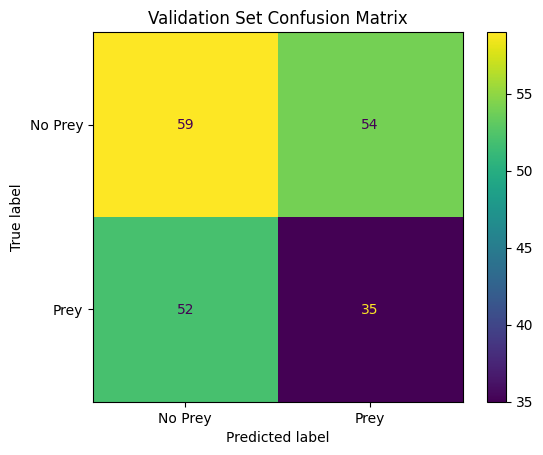

✅ Saved model as 'cat_prey_model.keras'
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
🧠 Prediction: No Prey (Confidence: 0.26%)
Ground truth: No Prey
🧠 Prediction: Prey (Confidence: 98.20%)
Ground truth: Prey
🧠 Prediction: No Prey (Confidence: 3.50%)
Ground truth: No Prey
🧠 Prediction: No Prey (Confidence: 4.57%)
Ground truth: No Prey
🧠 Prediction: Prey (Confidence: 98.46%)
Ground truth: Prey
Saved artifact at '/tmp/tmpxsbpqh21'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  138024582152656: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  138024582152272: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  138026223032784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138026223034320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138026223033744: TensorSpec(sh

W0000 00:00:1760190814.403222      35 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1760190814.403256      35 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1760190814.596743      35 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled


✅ TFLite model (float16) saved as 'cat_prey_model_fp16.tflite'


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import os
from collections import Counter

# Constants
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123
DATASET_PATH = "/kaggle/input/cleanpreycls/CleanPreyData"

# Load datasets
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# Quick class distribution check
class_names = train_ds.class_names
all_train_labels = np.concatenate([labels.numpy() for _, labels in train_ds.unbatch()])
label_counts = Counter(all_train_labels)
print("📊 Training class distribution:", {class_names[int(k)]: int(v) for k, v in label_counts.items()})

# Augmentation
def preprocess_and_augment(image, label):
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_flip_left_right(image)
    return image, label

def preprocess(image, label):
    return image, label

train_ds = train_ds.map(preprocess_and_augment, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)

# Prefetch
train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

# Model
base_model = EfficientNetB0(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(optimizer=Adam(1e-4), loss="binary_crossentropy", metrics=["accuracy"])

# Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)
]

# Train
print("🔧 Training...")
model.fit(train_ds, epochs=100, validation_data=val_ds, callbacks=callbacks)

# Evaluate
true_labels = np.concatenate([y.numpy() for _, y in val_ds.unbatch()])
pred_probs = model.predict(val_ds)
pred_labels = (pred_probs > 0.5).astype(int).flatten()

cm = confusion_matrix(true_labels.astype(int), pred_labels)
ConfusionMatrixDisplay(cm, display_labels=["No Prey", "Prey"]).plot()
plt.title("Validation Set Confusion Matrix")
plt.show()

# Save
model.save("cat_prey_model.keras")
print("✅ Saved model as 'cat_prey_model.keras'")

# Inspect predictions
for image, label in val_ds.take(1):
    preds = model.predict(image)
    for i in range(5):
        confidence = preds[i][0]
        print(f"🧠 Prediction: {'Prey' if confidence > 0.5 else 'No Prey'} (Confidence: {confidence:.2%})")
        print("Ground truth:", "Prey" if label[i].numpy() == 1 else "No Prey")

# Convert to TFLite (float16)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_model = converter.convert()

with open("cat_prey_model_fp16.tflite", "wb") as f:
    f.write(tflite_model)

print("✅ TFLite model (float16) saved as 'cat_prey_model_fp16.tflite'")
